# Detección temprana de estrés estudiantil con IA

**Proyecto final · Startup basada en Inteligencia Artificial** · *(nombre de la startup pendiente)*

Muchos estudiantes llegan al área de orientación cuando el estrés ya afectó sus calificaciones o su salud, o nunca llegan. Este notebook construye el **núcleo de IA** de una herramienta de autoevaluación: el alumno responde un formulario corto y el modelo estima si su nivel de estrés es **bajo, medio o alto**, junto con los factores que más pesan.

Lo que hace este notebook:

1. **Audita el dataset** antes de entrenar: de dónde viene cada fila y qué columnas son confiables.
2. **Define el uso de los datos**: qué columnas entran, cuáles se excluyen y por qué (minimización de datos).
3. Entrena y compara **líneas base**, *gradient boosting* y una **red neuronal Keras**.
4. **Exporta** el modelo para que la API (`.keras`), una app móvil (`.tflite`) y la web sin servidor (`pesos_web.json`) lo usen con el mismo **contrato de entradas**.
5. Propone un **estudio local** para validar y ajustar el modelo con estudiantes mexicanos.

> **Aviso.** El modelo es una herramienta de apoyo y **no hace diagnósticos clínicos**. Se entrenó con datos que **no son de México**; por eso el último paso propuesto es un estudio local.

## 1. Configuración

In [1]:
import os, json, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # oculta los avisos internos de TensorFlow (por ejemplo, sin GPU)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, ConfusionMatrixDisplay
import tensorflow as tf
import keras

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)       # fija numpy, random y TensorFlow
tf.get_logger().setLevel("ERROR")          # oculta mensajes informativos al exportar

RUTA_DATOS = "data/final_student_dataset.csv"
RUTA_MODELOS = "modelos"
CLASES = ["bajo", "medio", "alto"]

# Paleta (validada para daltonismo) y estilo de gráficas
AZUL, NARANJA, AQUA, ROJO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b", "#b5b4ad"
TINTA, TINTA_2 = "#0b0b0b", "#52514e"
COLOR_CLASE = [AQUA, NARANJA, ROJO]
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "legend.frameon": False,
})
pd.set_option("display.float_format", "{:.3f}".format)
print("TensorFlow", tf.__version__, "· Keras", keras.__version__)

TensorFlow 2.22.0-rc1 · Keras 3.16.0.dev2026111903


## 2. Los datos

Usamos el dataset de Kaggle **[Student Early Stress Detection](https://www.kaggle.com/datasets/rishavraj1232/student-early-stress-detection)** de Rishav Raj (versión 2): 289,161 filas y 39 columnas, sin valores faltantes.

- **Licencia:** la descripción dice CC BY 4.0 y los metadatos de Kaggle dicen CC BY-SA 4.0. Tomamos la más restrictiva (**CC BY-SA 4.0**) y citamos al autor y a sus fuentes.
- **No es un dataset de un solo origen.** El autor lo armó **juntando 6 fuentes** con alumnos distintos, y la columna `source_dataset` indica de cuál viene cada fila:

| `source_dataset` | Origen declarado por el autor |
| --- | --- |
| `oulad` | Open University Learning Analytics Dataset (Reino Unido) |
| `uci_dropout` | UCI 697, *Predict Students' Dropout and Academic Success* (Portugal) |
| `uci_performance` | UCI 320, *Student Performance* (Portugal) |
| `stress_survey` | Kaggle, *Student Stress Factors: A Comprehensive Analysis* (rxnach) |
| `mental_health` | Kaggle / Hyper.ai, *Student Mental Health and Burnout* |
| `dropout_risk_2026` | *Student Academic Performance & Dropout Risk 2026* |

Ningún alumno real tiene a la vez los clics de la plataforma de OULAD y una encuesta de estrés, así que muchas columnas de cada fila tuvieron que ser **imputadas**. Antes de entrenar hay que saber cuáles son confiables.

> El CSV no se sube al repositorio (pesa 56 MB). Para ejecutar el notebook, descárgalo de Kaggle y copia `final_student_dataset.csv` en `data/`.

In [2]:
datos = pd.read_csv(RUTA_DATOS)
print(f"{datos.shape[0]:,} filas · {datos.shape[1]} columnas · faltantes: {datos.isna().sum().sum()}")
datos["source_dataset"].value_counts().rename("filas").to_frame()

289,161 filas · 39 columnas · faltantes: 0


,filas
source_dataset,
mental_health,150000
dropout_risk_2026,100000
oulad,32593
uci_dropout,4424
stress_survey,1100
uci_performance,1044


## 3. Auditoría por fuente

Revisamos cada fuente por separado con tres pruebas:

1. **¿Se midió el estrés?** Cuántos valores distintos toman `stress_level_scale` y `anxiety_score`.
2. **¿Hay copias?** Si `anxiety_score` es idéntica a `stress_level_scale`, usar la ansiedad como entrada sería darle al modelo la respuesta (**fuga del objetivo**). También revisamos si la clase de estrés es simplemente `at_risk × 2`, es decir, si el estrés se dedujo de que el alumno reprobó.
3. **¿Hay señal?** Para cada columna, un árbol de profundidad 3 que usa **solo esa columna**. Si una sola columna acierta el 100 %, es fuga; si ninguna supera a la clase mayoritaria, es ruido.

In [3]:
OBJETIVO = "stress_level_3class"
CANDIDATAS = ["anxiety_score", "depression_score", "burnout_score", "sleep_hours_per_day", "study_hours_per_week",
              "social_support_score", "academic_pressure_score", "extracurricular_participation", "gpa_score_avg",
              "attendance_rate", "missed_submissions_count", "submission_lateness_days", "study_load"]

def auditar_fuente(g):
    """Resume si una fuente sirve para entrenar un modelo de estrés."""
    muestra = g.sample(min(len(g), 20_000), random_state=SEMILLA)
    mayoritaria = muestra[OBJETIVO].value_counts(normalize=True).max()
    acierto = {}
    for c in CANDIDATAS:
        if muestra[c].nunique() > 1:
            arbol = DecisionTreeClassifier(max_depth=3, random_state=SEMILLA)
            acierto[c] = cross_val_score(arbol, muestra[[c]], muestra[OBJETIVO], cv=3).mean()
    acierto = pd.Series(acierto)
    return pd.Series({
        "filas": len(g),
        "valores de estrés": g["stress_level_scale"].nunique(),
        "ansiedad = estrés": (g["anxiety_score"] == g["stress_level_scale"]).mean(),
        "clase = at_risk×2": (g[OBJETIVO] == 2 * g["at_risk"]).mean(),
        "acierto mayoritaria": mayoritaria,
        "mejor columna sola": acierto.idxmax(),
        "su acierto": acierto.max(),
        "mejor columna no copiada": acierto.drop(["anxiety_score", "depression_score", "burnout_score"]).idxmax(),
        "su acierto ": acierto.drop(["anxiety_score", "depression_score", "burnout_score"]).max(),
    })

auditoria = datos.groupby("source_dataset").apply(auditar_fuente, include_groups=False)
auditoria

,filas,valores de estrés,ansiedad = estrés,clase = at_risk×2,acierto mayoritaria,mejor columna sola,su acierto,mejor columna no copiada,su acierto
source_dataset,,,,,,,,,
dropout_risk_2026,100000,10,1.000,0.258,0.499,anxiety_score,1.000,sleep_hours_per_day,0.515
mental_health,150000,3,0.067,0.557,0.341,social_support_score,0.343,social_support_score,0.343
oulad,32593,2,1.000,1.000,0.528,anxiety_score,1.000,attendance_rate,0.808
stress_survey,1100,3,0.071,0.675,0.339,depression_score,0.879,sleep_hours_per_day,0.875
uci_dropout,4424,2,1.000,1.000,0.679,anxiety_score,1.000,gpa_score_avg,0.811
uci_performance,1044,2,1.000,1.000,0.780,anxiety_score,1.000,gpa_score_avg,1.000


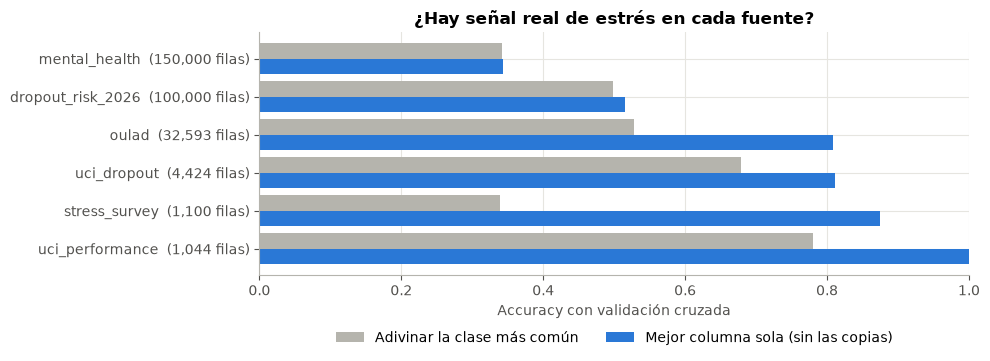

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
orden = auditoria.sort_values("filas").index
y = np.arange(len(orden))
ax.barh(y + 0.2, auditoria.loc[orden, "acierto mayoritaria"], height=0.4, color=GRIS, label="Adivinar la clase más común")
ax.barh(y - 0.2, auditoria.loc[orden, "su acierto "], height=0.4, color=AZUL, label="Mejor columna sola (sin las copias)")
ax.set_yticks(y, [f"{f}  ({int(auditoria.loc[f, 'filas']):,} filas)" for f in orden])
ax.set_xlim(0, 1); ax.set_xlabel("Accuracy con validación cruzada")
ax.set_title("¿Hay señal real de estrés en cada fuente?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.tight_layout(); plt.show()

**Lectura de la auditoría:**

| Fuente | Filas | Diagnóstico |
| --- | --- | --- |
| `mental_health` | 150,000 | **Ruido.** Ninguna columna supera a adivinar (≈ 34 %). Los valores parecen generados al azar |
| `dropout_risk_2026` | 100,000 | **Fuga del objetivo.** `anxiety_score` es idéntica a `stress_level_scale` en el 100 % de las filas, y la depresión y el burnout son copias reescaladas. Fuera de eso, nada predice |
| `oulad`, `uci_dropout`, `uci_performance` | 38,061 | **Estrés inventado.** La clase es exactamente `at_risk × 2`: el estrés se dedujo de si el alumno reprobó. En estas fuentes nunca se midió estrés |
| `stress_survey` | **1,100** | **La única fuente con señal real.** Las escalas psicológicas no son copias del estrés y varias columnas se relacionan con él |

En la gráfica, `oulad` y las dos fuentes UCI parecen tener señal, pero es engañosa: el promedio y la asistencia "predicen" el estrés solo porque la clase se dedujo de la reprobación (`at_risk`), y el promedio predice la reprobación.

**Decisión:** entrenamos **solo con las 1,100 filas de `stress_survey`**. Si usáramos las 289 mil, el modelo aprendería la copia `ansiedad = estrés` y el ruido, y daría métricas altas pero falsas.

## 4. Uso de columnas

Dentro de `stress_survey`, muchas columnas son **constantes** (se rellenaron con un mismo valor) y otras no se pueden pedir en un formulario. Aplicamos tres criterios:

1. **Que el alumno la conozca de sí mismo.** La herramienta es una autoevaluación; el alumno no sabe su `lms_engagement_score`.
2. **Minimización de datos.** No pedimos datos sensibles si no mejoran el modelo (Ley Federal de Protección de Datos Personales en Posesión de los Particulares, LFPDPPP).
3. **Que no sea el objetivo disfrazado.** Nada que se haya calculado a partir del estrés.

In [5]:
encuesta = datos[datos["source_dataset"] == "stress_survey"].reset_index(drop=True)
numericas = encuesta.select_dtypes("number").columns
distintos = encuesta[numericas].nunique()
constantes, varian = distintos.index[distintos == 1], distintos.index[distintos > 1]
print("Columnas constantes en stress_survey:", ", ".join(constantes))
pd.DataFrame({
    "valores distintos": distintos[varian],
    "corr. con estrés (Spearman)": encuesta[varian].corrwith(encuesta["stress_level_scale"], method="spearman"),
}).sort_values("corr. con estrés (Spearman)")

Columnas constantes en stress_survey: age, disability_flag, international_student, first_generation, socioeconomic_deprivation_index, scholarship_holder, tuition_up_to_date, admission_grade, prior_qualification_grade, prior_attempts, gpa_score_trend, study_load, attendance_rate, lms_engagement_score, engagement_trend, longest_inactivity_gap_days, submission_lateness_days, missed_submissions_count


,valores distintos,corr. con estrés (Spearman)
final_score_pct,12,-0.889
pass_rate,2,-0.867
sleep_hours_per_day,6,-0.761
gpa_score_avg,6,-0.728
first_assessment_score,929,-0.708
social_support_score,4,-0.644
academic_pressure_score,11,-0.191
lms_active_days_ratio,905,-0.002
gender_encoded,2,0.013
extracurricular_participation,2,0.660


| Grupo | Columnas | Decisión y motivo |
| --- | --- | --- |
| Objetivo y derivadas | `stress_level_3class` (objetivo), `stress_level_scale`, `at_risk`, `final_score_pct`, `needs_help_score`, `needs_help_band` | **Excluidas.** La clase sale de `stress_level_scale` (0, 5 y 10 → bajo, medio, alto) y las demás se calcularon combinando el estrés con lo académico |
| Demográficas y económicas | `age`, `gender_encoded`, `disability_flag`, `international_student`, `first_generation`, `socioeconomic_deprivation_index`, `scholarship_holder`, `tuition_up_to_date` | **Excluidas.** Casi todas son constantes en esta fuente (el índice socioeconómico vale 5 para todos), no representan a México y son sensibles. `gender_encoded` solo se usa *fuera* del modelo, para revisar sesgos |
| Institucionales | `pass_rate`, `first_assessment_score`, `lms_active_days_ratio`, `lms_engagement_score`, `attendance_rate`, `engagement_trend`, `longest_inactivity_gap_days`, `submission_lateness_days`, `missed_submissions_count`, `gpa_score_trend`, `study_load`, `prior_attempts` | **Excluidas.** El alumno no las conoce. Además, `pass_rate` es el espejo de `at_risk` (correlación −1.00), `first_assessment_score` es el promedio con ruido (0.97) y `lms_active_days_ratio` es ruido (0.00) |
| Escalas extranjeras | `admission_grade`, `prior_qualification_grade` | **Excluidas.** Constantes en esta fuente y en escalas de Portugal o Reino Unido |
| Escalas clínicas | `anxiety_score`, `depression_score`, `burnout_score` | **Excluidas del modelo final.** Sus rangos (22 y 28 valores) corresponden a cuestionarios clínicos de ansiedad y depresión, y `burnout_score` es una combinación de ambas (correlación 0.90 y 0.94). La sección 9 muestra que **quitarlas no le cuesta precisión al modelo**, así que no se piden |
| **Hábitos y contexto** | `sleep_hours_per_day`, `study_hours_per_week`, `social_support_score`, `academic_pressure_score`, `extracurricular_participation`, `gpa_score_avg` | **Entradas del modelo.** Son preguntas que cualquier alumno puede contestar sin dar información clínica |

**Sobre fijar el nivel socioeconómico en "medio" para todos.** Lo correcto es excluir la columna desde el entrenamiento: si el modelo aprendiera con el índice variando y en la web siempre recibiera "medio", evaluaría a todos como si fueran de nivel medio y se equivocaría en silencio con los extremos. En esta fuente el problema ni siquiera existe: el índice ya es constante, así que excluirlo no cuesta nada.

In [6]:
ENTRADAS = ["sleep_hours_per_day", "study_hours_per_week", "social_support_score",
            "academic_pressure_score", "extracurricular_participation", "gpa_score_avg"]
CLINICAS = ["anxiety_score", "depression_score", "burnout_score"]

X_todo = encuesta[ENTRADAS].astype("float32").to_numpy()
y_todo = encuesta[OBJETIVO].to_numpy()
encuesta[ENTRADAS].describe().T[["min", "max", "mean", "std"]].assign(
    valores=encuesta[ENTRADAS].nunique())

,min,max,mean,std,valores
sleep_hours_per_day,4.000,8.000,6.128,1.239,6
study_hours_per_week,4.000,20.000,10.622,5.039,5
social_support_score,0.000,10.000,6.273,3.493,4
academic_pressure_score,0.000,10.000,5.395,1.340,11
extracurricular_participation,0.000,1.000,0.500,0.500,2
gpa_score_avg,0.000,100.000,55.455,28.292,6


## 5. Análisis exploratorio

Alumnos por clase: {'bajo': 373, 'medio': 358, 'alto': 369}


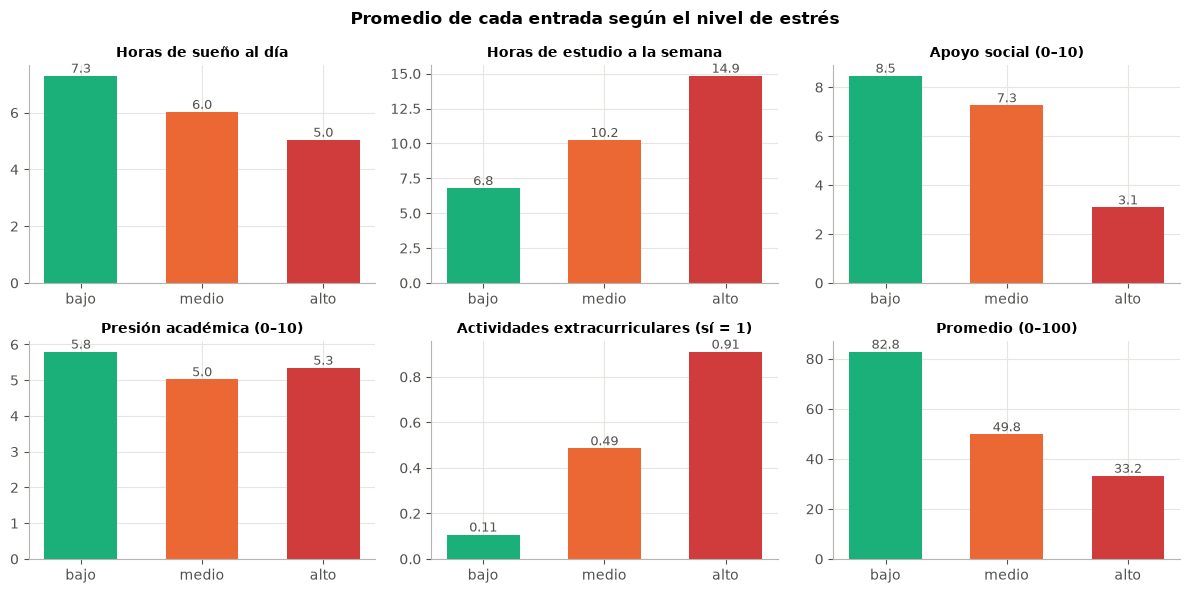

In [7]:
conteo = encuesta[OBJETIVO].value_counts().sort_index()
print("Alumnos por clase:", dict(zip(CLASES, conteo.tolist())))

etiquetas = {"sleep_hours_per_day": "Horas de sueño al día", "study_hours_per_week": "Horas de estudio a la semana",
             "social_support_score": "Apoyo social (0–10)", "academic_pressure_score": "Presión académica (0–10)",
             "extracurricular_participation": "Actividades extracurriculares (sí = 1)",
             "gpa_score_avg": "Promedio (0–100)"}
fig, ejes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(ejes.ravel(), ENTRADAS):
    medias = encuesta.groupby(OBJETIVO)[c].mean()
    ax.bar(CLASES, medias.values, color=COLOR_CLASE, width=0.6)
    for i, v in enumerate(medias.values):
        ax.text(i, v, f"{v:.1f}" if v >= 1 else f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=TINTA_2)
    ax.set_title(etiquetas[c], fontsize=10)
fig.suptitle("Promedio de cada entrada según el nivel de estrés", fontweight="bold")
plt.tight_layout(); plt.show()

**Lectura:**
- Las clases están **balanceadas** (≈ 1/3 cada una), así que no hacen falta pesos de clase.
- El estrés alto viene con **menos sueño** (5.0 h contra 7.3 h), **menos apoyo social**, **más horas de estudio** y **promedio más bajo**.
- Dos relaciones llaman la atención: quienes hacen actividades extracurriculares reportan **más** estrés, y la presión académica casi no cambia entre clases. Las reportamos tal como salen; el estudio local dirá si se repiten en México.
- Las diferencias son **muy marcadas**. Esto anticipa que el problema es fácil *en este dataset* y que la precisión real con alumnos mexicanos probablemente será menor.

## 6. División de los datos

División **estratificada** (misma proporción de clases en cada parte): 70 % entrenamiento, 15 % validación (para `EarlyStopping`) y 15 % prueba, que solo se usa al final.

In [8]:
idx = np.arange(len(encuesta))
idx_ent, idx_prueba = train_test_split(idx, test_size=0.15, stratify=y_todo, random_state=SEMILLA)
idx_ent, idx_val = train_test_split(idx_ent, test_size=0.15 / 0.85, stratify=y_todo[idx_ent], random_state=SEMILLA)
X_ent, X_val, X_prueba = X_todo[idx_ent], X_todo[idx_val], X_todo[idx_prueba]
y_ent, y_val, y_prueba = y_todo[idx_ent], y_todo[idx_val], y_todo[idx_prueba]
print(f"Entrenamiento: {len(idx_ent)} · validación: {len(idx_val)} · prueba: {len(idx_prueba)}")

Entrenamiento: 770 · validación: 165 · prueba: 165


## 7. Líneas base

- **Clase mayoritaria:** siempre responde la clase más común. Es el piso.
- **Regresión logística** con `StandardScaler`.
- **`HistGradientBoostingClassifier`:** el modelo de árboles de referencia.

Se entrenan con entrenamiento + validación (no usan *early stopping*) y se evalúan en prueba. La métrica principal es el **F1 macro** (promedio del F1 de las 3 clases), y vigilamos el **recall de la clase alta**: no detectar a un alumno con estrés alto es el error más costoso.

In [9]:
X_ev, y_ev = np.vstack([X_ent, X_val]), np.concatenate([y_ent, y_val])

def evaluar(nombre, y_real, y_pred):
    return {"modelo": nombre, "accuracy": accuracy_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro"),
            "recall alto": recall_score(y_real, y_pred, average=None)[2]}

bases = {
    "Clase mayoritaria": DummyClassifier(strategy="most_frequent"),
    "Regresión logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=SEMILLA),
}
resultados = []
for nombre, modelo in bases.items():
    modelo.fit(X_ev, y_ev)
    resultados.append(evaluar(nombre, y_prueba, modelo.predict(X_prueba)))
pd.DataFrame(resultados).set_index("modelo")

,accuracy,F1 macro,recall alto
modelo,,,
Clase mayoritaria,0.339,0.169,0.000
Regresión logística,0.879,0.879,0.945
Gradient boosting,0.879,0.878,0.927


## 8. Red neuronal Keras

Una red `Sequential` pequeña (como en la Clase 05), con un detalle importante para el despliegue: la **primera capa es `Normalization`**, adaptada solo con los datos de entrenamiento. Así el modelo exportado recibe los **valores tal como los captura el formulario** y la API, la app y la web no tienen que repetir el escalado.

- Arquitectura: `Normalization` → Dense 64 (ReLU) → Dense 32 (ReLU) → Dense 3 (softmax).
- Pérdida `sparse_categorical_crossentropy` con Adam.
- `EarlyStopping` con paciencia 15 sobre la pérdida de validación, restaurando los mejores pesos (Clase 07).

In [10]:
def crear_red(X_adaptar, n_entradas):
    normalizacion = keras.layers.Normalization(name="normalizacion")
    normalizacion.adapt(X_adaptar)
    red = keras.Sequential([
        keras.Input(shape=(n_entradas,), name="respuestas"),
        normalizacion,
        keras.layers.Dense(64, activation="relu", name="oculta_1"),
        keras.layers.Dense(32, activation="relu", name="oculta_2"),
        keras.layers.Dense(3, activation="softmax", name="probabilidades"),
    ], name="modelo_estres")
    red.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return red

parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
keras.utils.set_random_seed(SEMILLA)
red = crear_red(X_ent, len(ENTRADAS))
historia = red.fit(X_ent, y_ent, validation_data=(X_val, y_val), epochs=300, batch_size=32,
                   callbacks=[parada], verbose=0)
mejor = int(np.argmin(historia.history["val_loss"])) + 1
print(f"Épocas entrenadas: {len(historia.history['loss'])} · mejor época: {mejor}")
red.summary()

Épocas entrenadas: 33 · mejor época: 18


Model: "modelo_estres"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalizacion (Normalization)   │ (None, 6)              │            13 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 64)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probabilidades (Dense)          │ (None, 3)              │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,896 (30.85 KB)

 Trainable params: 2,627 (10.26 KB)

 Non-trainable params: 13 (56.00 B)

 Optimizer params: 5,256 (20.54 KB)

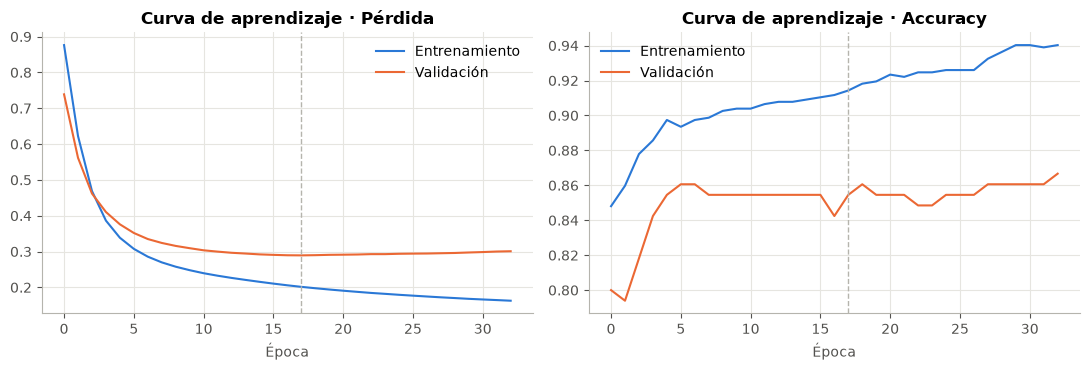

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, m, titulo in [(a1, "loss", "Pérdida"), (a2, "accuracy", "Accuracy")]:
    ax.plot(historia.history[m], color=AZUL, label="Entrenamiento")
    ax.plot(historia.history[f"val_{m}"], color=NARANJA, label="Validación")
    ax.axvline(mejor - 1, color=GRIS, ls="--", lw=1)
    ax.set_title(f"Curva de aprendizaje · {titulo}"); ax.set_xlabel("Época"); ax.legend()
plt.tight_layout(); plt.show()

Las curvas de entrenamiento y validación van juntas y la validación se estabiliza en pocas épocas: con 6 entradas y 770 alumnos de entrenamiento, la red no sobreajusta y `EarlyStopping` la detiene a tiempo.

## 9. Evaluación en prueba

In [12]:
prob_prueba = red.predict(X_prueba, verbose=0)
pred_red = prob_prueba.argmax(axis=1)
resultados.append(evaluar("Red Keras", y_prueba, pred_red))
tabla = pd.DataFrame(resultados).set_index("modelo")
print("Recall por clase de la red:", {c: round(float(v), 3) for c, v in zip(CLASES, recall_score(y_prueba, pred_red, average=None))})
tabla

Recall por clase de la red: {'bajo': 0.786, 'medio': 0.889, 'alto': 0.909}


,accuracy,F1 macro,recall alto
modelo,,,
Clase mayoritaria,0.339,0.169,0.000
Regresión logística,0.879,0.879,0.945
Gradient boosting,0.879,0.878,0.927
Red Keras,0.861,0.860,0.909


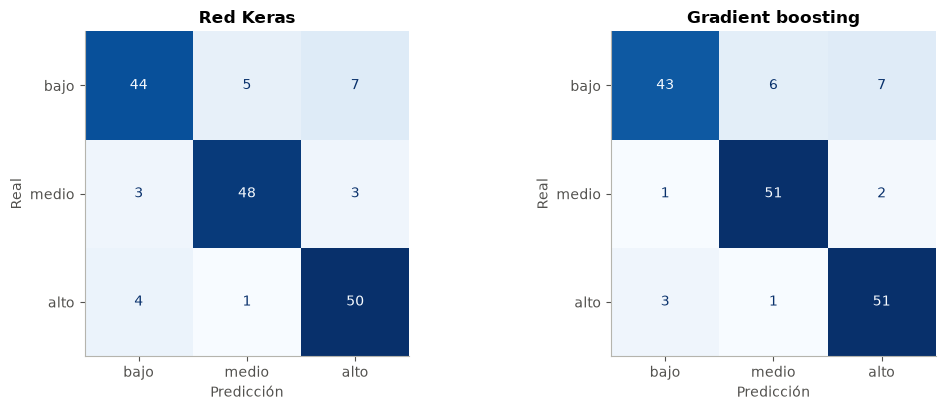

In [13]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
pred_gb = bases["Gradient boosting"].predict(X_prueba)
for ax, pred, titulo in [(a1, pred_red, "Red Keras"), (a2, pred_gb, "Gradient boosting")]:
    ConfusionMatrixDisplay.from_predictions(y_prueba, pred, display_labels=CLASES, cmap="Blues",
                                            colorbar=False, ax=ax)
    ax.set_title(titulo); ax.grid(False)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

La prueba tiene solo 165 alumnos: una diferencia de 0.02 en F1 equivale a unos 3 alumnos. Para comparar con justicia, repetimos el entrenamiento de la red con **validación cruzada de 5 particiones** sobre entrenamiento + validación, igual que las líneas base. En cada partición se aparta un 15 % para `EarlyStopping`.

In [14]:
def f1_cv_red(X, y):
    f1s = []
    for i_ent, i_ev in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y):
        i_ent, i_pa = train_test_split(i_ent, test_size=0.15, stratify=y[i_ent], random_state=SEMILLA)
        keras.utils.set_random_seed(SEMILLA)
        modelo = crear_red(X[i_ent], X.shape[1])
        modelo.fit(X[i_ent], y[i_ent], validation_data=(X[i_pa], y[i_pa]), epochs=300, batch_size=32,
                   callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)],
                   verbose=0)
        f1s.append(f1_score(y[i_ev], modelo.predict(X[i_ev], verbose=0).argmax(1), average="macro"))
    return np.array(f1s)

validacion_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
comparacion = {"Red Keras": f1_cv_red(X_ev, y_ev)}
for nombre in ["Regresión logística", "Gradient boosting"]:
    comparacion[nombre] = cross_val_score(bases[nombre], X_ev, y_ev, cv=validacion_cruzada, scoring="f1_macro")
pd.DataFrame({"F1 macro (media)": {k: v.mean() for k, v in comparacion.items()},
              "desv. estándar": {k: v.std() for k, v in comparacion.items()}})

,F1 macro (media),desv. estándar
Red Keras,0.889,0.008
Regresión logística,0.878,0.016
Gradient boosting,0.895,0.007


**Lectura:**
- En la prueba de 165 alumnos, la red (F1 0.86) queda unos 2 puntos debajo de la regresión logística y del *gradient boosting* (0.88), es decir, unos 3 alumnos. Con validación cruzada, la red obtiene **0.89 ± 0.01**, entre la logística (0.88) y el *gradient boosting* (0.90). **Los tres modelos están empatados**; con datos tan separables, el algoritmo no es lo que marca la diferencia.
- Elegimos la **red Keras** para producción porque es la única de las tres que se exporta a TFLite y que se puede ejecutar en el navegador o en el celular sin servidor.
- **Recall de la clase alta: 0.91** (50 de 55). De los 5 alumnos con estrés alto que no detecta, 4 quedan como "bajo", el error más grave. En el producto se mitiga mostrando siempre los factores y la invitación a orientación, sin importar el nivel.
- El error más común es clasificar a un alumno de estrés bajo como medio o alto (12 de 56). Cuesta poco: una invitación de más a orientación.

## 10. ¿Cuánto cuesta pedir menos datos? (ablaciones)

Comparamos distintos conjuntos de entradas con **validación cruzada de 5 particiones** sobre entrenamiento + validación. Así la comparación no depende de una sola división. Usamos regresión logística y *gradient boosting* porque entrenan en segundos.

In [15]:
validacion_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
encuesta_ev = encuesta.iloc[np.concatenate([idx_ent, idx_val])]

conjuntos = {
    "Hábitos + escalas clínicas (9)": ENTRADAS + CLINICAS,
    "Hábitos + ansiedad y depresión (8)": ENTRADAS + ["anxiety_score", "depression_score"],
    "Solo hábitos · modelo final (6)": ENTRADAS,
    "Solo sueño, apoyo social y presión (3)": ["sleep_hours_per_day", "social_support_score", "academic_pressure_score"],
    "Solo horas de sueño (1)": ["sleep_hours_per_day"],
}
filas = []
for nombre, columnas in conjuntos.items():
    fila = {"conjunto": nombre}
    for etiqueta, modelo in [("logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
                             ("gradient boosting", HistGradientBoostingClassifier(random_state=SEMILLA))]:
        f1 = cross_val_score(modelo, encuesta_ev[columnas], encuesta_ev[OBJETIVO],
                             cv=validacion_cruzada, scoring="f1_macro")
        fila[f"F1 {etiqueta}"] = f1.mean()
        fila[f"± {etiqueta}"] = f1.std()
    filas.append(fila)
ablacion = pd.DataFrame(filas).set_index("conjunto")
ablacion

,F1 logística,± logística,F1 gradient boosting,± gradient boosting
conjunto,,,,
Hábitos + escalas clínicas (9),0.881,0.021,0.884,0.016
Hábitos + ansiedad y depresión (8),0.881,0.021,0.883,0.004
Solo hábitos · modelo final (6),0.878,0.016,0.895,0.007
"Solo sueño, apoyo social y presión (3)",0.876,0.018,0.894,0.018
Solo horas de sueño (1),0.875,0.019,0.871,0.018


**Lectura:**
- **Quitar las escalas clínicas no cuesta precisión.** El modelo con 6 preguntas de hábitos rinde igual que con ansiedad, depresión y burnout. Por eso el formulario **no pide información clínica**, lo que reduce el riesgo de tratar datos sensibles y hace la herramienta menos invasiva.
- **Advertencia honesta:** con solo 1 variable (horas de sueño) el modelo ya acierta mucho. Que un fenómeno tan complejo como el estrés se prediga casi con una sola pregunta indica que este dataset es **demasiado limpio**, y posiblemente sintético en parte. Las métricas de este notebook son un **techo optimista**; las reales se medirán en el estudio local (sección 15).
- Nos quedamos con 6 entradas y no con 3. Cuesta muy poco pedir 3 preguntas más, y le da al estudio local la oportunidad de medir qué variables importan de verdad en México.

## 11. Interpretabilidad

**Importancia por permutación** sobre la red: se revuelve una columna de prueba a la vez y se mide cuánto cae el F1 macro. Si cae mucho, el modelo depende de esa columna.

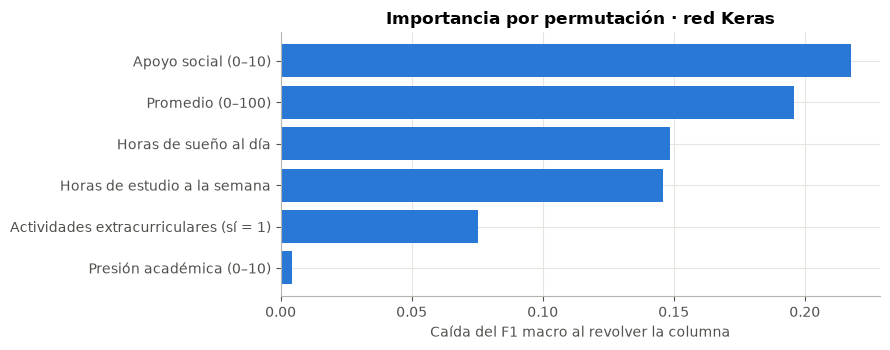

In [16]:
def importancia_permutacion(modelo, X, y, repeticiones=20):
    rng = np.random.default_rng(SEMILLA)
    base = f1_score(y, modelo.predict(X, verbose=0).argmax(1), average="macro")
    caidas = {}
    for j, c in enumerate(ENTRADAS):
        valores = []
        for _ in range(repeticiones):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            valores.append(base - f1_score(y, modelo.predict(Xp, verbose=0).argmax(1), average="macro"))
        caidas[etiquetas[c]] = np.mean(valores)
    return pd.Series(caidas).sort_values()

importancia = importancia_permutacion(red, X_prueba, y_prueba)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(importancia.index, importancia.values, color=AZUL)
ax.set_xlabel("Caída del F1 macro al revolver la columna")
ax.set_title("Importancia por permutación · red Keras")
plt.tight_layout(); plt.show()

El **apoyo social**, el **promedio** y las **horas de sueño** son lo que más usa la red. La **presión académica casi no aporta**: es candidata a salir del formulario si el estudio local lo confirma. Esta información alimenta el mensaje de la web: además del nivel estimado, se muestran **los factores que más empujan hacia el estrés** en las respuestas de cada alumno (sección 13).

## 12. Revisión de sesgos

`gender_encoded` **no es entrada del modelo**. Solo la usamos para revisar si el modelo se equivoca más con un grupo que con otro. Una limitación: no sabemos si esta columna es real o fue imputada por el autor del dataset.

In [17]:
genero_prueba = encuesta["gender_encoded"].to_numpy()[idx_prueba]
sesgo = []
for g in np.unique(genero_prueba):
    m = genero_prueba == g
    sesgo.append({"gender_encoded": g, "alumnos": int(m.sum()),
                  **{k: v for k, v in evaluar("", y_prueba[m], pred_red[m]).items() if k != "modelo"}})
pd.DataFrame(sesgo).set_index("gender_encoded")

,alumnos,accuracy,F1 macro,recall alto
gender_encoded,,,,
0,86,0.884,0.884,0.893
1,79,0.835,0.833,0.926


Las métricas por grupo son similares; las diferencias que aparecen están dentro de lo esperable con ~80 alumnos por grupo. El estudio local debe repetir esta revisión con datos mexicanos y con más grupos (por ejemplo, semestre y carrera).

## 13. Demostración: lo que vería el alumno

La función `evaluar_alumno` recibe las respuestas **tal como las pide el formulario** (el promedio en escala mexicana de 0 a 10) y devuelve el nivel estimado, las probabilidades y los factores que más pesan. Los factores se calculan comparando cada respuesta con el promedio de entrenamiento, en la dirección en que esa variable se relaciona con el estrés.

In [18]:
media_ent = X_ent.mean(axis=0)
desv_ent = X_ent.std(axis=0)
direccion = np.sign(encuesta.iloc[idx_ent][ENTRADAS].corrwith(encuesta.iloc[idx_ent]["stress_level_scale"],
                                                             method="spearman").to_numpy())
TEXTO_FACTOR = {
    "sleep_hours_per_day": "duermes pocas horas", "study_hours_per_week": "muchas horas de estudio a la semana",
    "social_support_score": "poco apoyo de familia o amigos", "academic_pressure_score": "presión académica",
    "extracurricular_participation": "carga de actividades extracurriculares", "gpa_score_avg": "promedio bajo",
}
MENSAJE = {
    "bajo": "Tus respuestas indican un nivel de estrés bajo. Sigue cuidando tus hábitos.",
    "medio": "Tus respuestas indican un nivel de estrés medio. Revisa los factores señalados.",
    "alto": "Tus respuestas indican un nivel de estrés alto. Te recomendamos acercarte al área de orientación de tu escuela.",
}

def respuestas_a_entradas(r):
    """Convierte las respuestas del formulario a las unidades del modelo (ver contrato.json)."""
    return np.array([[r["horas_sueno"], r["horas_estudio_semana"], r["apoyo_social"],
                      r["presion_academica"], float(r["extracurriculares"]), r["promedio_0a10"] * 10]],
                    dtype="float32")

def evaluar_alumno(respuestas, modelo=red):
    x = respuestas_a_entradas(respuestas)
    p = modelo.predict(x, verbose=0)[0]
    nivel = CLASES[int(p.argmax())]
    empuje = direccion * (x[0] - media_ent) / desv_ent      # > 0: empuja hacia más estrés
    factores = [TEXTO_FACTOR[ENTRADAS[j]] for j in np.argsort(-empuje)[:2] if empuje[j] > 0.5]
    return {"nivel": nivel, "probabilidades": {c: round(float(v), 3) for c, v in zip(CLASES, p)},
            "factores": factores, "mensaje": MENSAJE[nivel] + " *No es un diagnóstico.*"}

ejemplos = {
    "Ana":  dict(horas_sueno=7.5, horas_estudio_semana=8,  apoyo_social=10,  presion_academica=5, extracurriculares=0, promedio_0a10=9.0),
    "Beto": dict(horas_sueno=6.0, horas_estudio_semana=12, apoyo_social=6.7, presion_academica=5, extracurriculares=1, promedio_0a10=6.0),
    "Caro": dict(horas_sueno=4.5, horas_estudio_semana=18, apoyo_social=0,   presion_academica=6, extracurriculares=1, promedio_0a10=4.0),
}
for nombre, r in ejemplos.items():
    res = evaluar_alumno(r)
    print(f"{nombre}: {res['nivel'].upper()} {res['probabilidades']}")
    print(f"   factores: {', '.join(res['factores']) or 'ninguno destacado'}")
    print(f"   {res['mensaje']}")

Ana: BAJO {'bajo': 0.995, 'medio': 0.004, 'alto': 0.001}
   factores: ninguno destacado
   Tus respuestas indican un nivel de estrés bajo. Sigue cuidando tus hábitos. *No es un diagnóstico.*
Beto: MEDIO {'bajo': 0.018, 'medio': 0.915, 'alto': 0.067}
   factores: carga de actividades extracurriculares
   Tus respuestas indican un nivel de estrés medio. Revisa los factores señalados. *No es un diagnóstico.*
Caro: ALTO {'bajo': 0.022, 'medio': 0.007, 'alto': 0.971}
   factores: poco apoyo de familia o amigos, muchas horas de estudio a la semana
   Tus respuestas indican un nivel de estrés alto. Te recomendamos acercarte al área de orientación de tu escuela. *No es un diagnóstico.*


## 14. Exportación

Todo lo que necesitan la API, la app y la web queda en `modelos/`:

| Archivo | Para quién | Uso |
| --- | --- | --- |
| `modelo_estres.keras` | API (FastAPI) | `keras.models.load_model(...)` y `predict` |
| `modelo_estres.tflite` | App móvil, o web con TFLite en el navegador | Intérprete TFLite / LiteRT |
| `pesos_web.json` | Web sin servidor | Pesos y normalización en JSON: la red se calcula con unas cuantas multiplicaciones de matrices en JavaScript |
| `contrato.json` | Todos | **La interfaz común**: orden, unidades y rangos de las entradas, conversión desde el formulario, clases de salida, textos y métricas |

Al final se verifica que **Keras, TFLite y el cálculo manual con los pesos del JSON den las mismas probabilidades**.

> Se intentó exportar con el convertidor oficial de TensorFlow.js, pero no es compatible con Python 3.14 (instalarlo obliga a degradar dependencias de Jupyter). Para una red de este tamaño, `pesos_web.json` es más simple y no requiere librerías.

In [19]:
os.makedirs(RUTA_MODELOS, exist_ok=True)

# 1) Keras (API)
red.save(f"{RUTA_MODELOS}/modelo_estres.keras")

# 2) TFLite (móvil / navegador)
red.export(f"{RUTA_MODELOS}/saved_model", format="tf_saved_model", verbose=False)
convertidor = tf.lite.TFLiteConverter.from_saved_model(f"{RUTA_MODELOS}/saved_model")
with open(f"{RUTA_MODELOS}/modelo_estres.tflite", "wb") as f:
    f.write(convertidor.convert())

# 3) Pesos en JSON (web sin servidor)
capa_norm = red.get_layer("normalizacion")
pesos_web = {
    "entradas": ENTRADAS,
    "normalizacion": {"media": np.asarray(capa_norm.mean).ravel().tolist(),
                      "varianza": np.asarray(capa_norm.variance).ravel().tolist(),
                      "epsilon": float(keras.config.epsilon())},
    "capas": [{"W": capa.get_weights()[0].tolist(), "b": capa.get_weights()[1].tolist(),
               "activacion": capa.activation.__name__} for capa in red.layers if isinstance(capa, keras.layers.Dense)],
}
with open(f"{RUTA_MODELOS}/pesos_web.json", "w") as f:
    json.dump(pesos_web, f)
print("Archivos:", sorted(os.listdir(RUTA_MODELOS)))

Archivos: ['contrato.json', 'modelo_estres.keras', 'modelo_estres.tflite', 'pesos_web.json', 'referencia_gradient_boosting.joblib', 'saved_model']


In [20]:
# 4) Contrato de entradas y salidas
metricas_red = tabla.loc["Red Keras"]
contrato = {
    "modelo": "modelo_estres", "version": "1.0.0", "semilla": SEMILLA,
    "datos": "Kaggle rishavraj1232/student-early-stress-detection v2, solo source_dataset == 'stress_survey' (1,100 filas)",
    "orden_entradas": ENTRADAS,
    "entradas": [
        {"nombre": "sleep_hours_per_day", "campo_formulario": "horas_sueno", "pregunta": "¿Cuántas horas duermes al día, en promedio?",
         "unidad": "horas", "min": 4.0, "max": 8.0, "conversion": "valor tal cual; recortar al rango [4, 8]"},
        {"nombre": "study_hours_per_week", "campo_formulario": "horas_estudio_semana", "pregunta": "¿Cuántas horas estudias a la semana fuera de clase?",
         "unidad": "horas por semana", "min": 4.0, "max": 20.0, "conversion": "valor tal cual; recortar al rango [4, 20]"},
        {"nombre": "social_support_score", "campo_formulario": "apoyo_social", "pregunta": "¿Cuánto apoyo sientes de tu familia y amigos?",
         "unidad": "escala 0–10", "min": 0.0, "max": 10.0,
         "conversion": "opciones: nada = 0, poco = 3.3, bastante = 6.7, mucho = 10"},
        {"nombre": "academic_pressure_score", "campo_formulario": "presion_academica", "pregunta": "Del 0 al 10, ¿cuánta presión académica sientes?",
         "unidad": "escala 0–10", "min": 0.0, "max": 10.0, "conversion": "valor tal cual (entero 0–10)"},
        {"nombre": "extracurricular_participation", "campo_formulario": "extracurriculares", "pregunta": "¿Participas en actividades extracurriculares?",
         "unidad": "sí/no", "min": 0.0, "max": 1.0, "conversion": "sí = 1, no = 0"},
        {"nombre": "gpa_score_avg", "campo_formulario": "promedio_0a10", "pregunta": "¿Cuál es tu promedio aproximado (0 a 10)?",
         "unidad": "promedio 0–100", "min": 0.0, "max": 100.0, "conversion": "promedio en escala 0–10 multiplicado por 10"},
    ],
    "salida": {"tipo": "probabilidades softmax, en el orden de 'clases'",
               "clases": [{"id": i, "etiqueta": c, "mensaje": MENSAJE[c]} for i, c in enumerate(CLASES)]},
    "explicacion": {"descripcion": "empuje = direccion * (x - media) / desv; se muestran los 2 factores con empuje > 0.5",
                    "media": media_ent.tolist(), "desv": desv_ent.tolist(), "direccion": direccion.tolist(),
                    "textos": [TEXTO_FACTOR[c] for c in ENTRADAS]},
    "metricas_prueba": {k: round(float(v), 4) for k, v in metricas_red.items()},
    "archivos": {"api": "modelo_estres.keras", "movil": "modelo_estres.tflite", "web": "pesos_web.json"},
    "aviso": "Herramienta de apoyo. No es un diagnóstico clínico. Entrenado con datos que no son de México.",
}
with open(f"{RUTA_MODELOS}/contrato.json", "w", encoding="utf-8") as f:
    json.dump(contrato, f, ensure_ascii=False, indent=2)
joblib.dump(bases["Gradient boosting"], f"{RUTA_MODELOS}/referencia_gradient_boosting.joblib")
print(json.dumps(contrato["entradas"][0], ensure_ascii=False, indent=2))

{
  "nombre": "sleep_hours_per_day",
  "campo_formulario": "horas_sueno",
  "pregunta": "¿Cuántas horas duermes al día, en promedio?",
  "unidad": "horas",
  "min": 4.0,
  "max": 8.0,
  "conversion": "valor tal cual; recortar al rango [4, 8]"
}


In [21]:
# 5) Verificación: Keras, TFLite y el cálculo manual con pesos_web.json dan lo mismo
X_ejemplos = np.vstack([respuestas_a_entradas(r) for r in ejemplos.values()] + [X_prueba[:20]])

p_keras = keras.models.load_model(f"{RUTA_MODELOS}/modelo_estres.keras").predict(X_ejemplos, verbose=0)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")            # tf.lite.Interpreter avisa que en el futuro se llamará LiteRT
    interprete = tf.lite.Interpreter(
        model_path=f"{RUTA_MODELOS}/modelo_estres.tflite",
        experimental_op_resolver_type=tf.lite.experimental.OpResolverType.BUILTIN_WITHOUT_DEFAULT_DELEGATES)
interprete.allocate_tensors()
ent, sal = interprete.get_input_details()[0], interprete.get_output_details()[0]
p_tflite = []
for fila in X_ejemplos:
    interprete.set_tensor(ent["index"], fila[None, :]); interprete.invoke()
    p_tflite.append(interprete.get_tensor(sal["index"])[0])
p_tflite = np.array(p_tflite)

def red_manual(X, pesos):
    """Lo mismo que hará la web en JavaScript: normalizar y multiplicar matrices."""
    n = pesos["normalizacion"]
    h = (X - np.array(n["media"])) / np.maximum(np.sqrt(np.array(n["varianza"])), n["epsilon"])
    for capa in pesos["capas"]:
        h = h @ np.array(capa["W"]) + np.array(capa["b"])
        if capa["activacion"] == "relu":
            h = np.maximum(h, 0)
        elif capa["activacion"] == "softmax":
            h = np.exp(h - h.max(axis=1, keepdims=True)); h = h / h.sum(axis=1, keepdims=True)
    return h

with open(f"{RUTA_MODELOS}/pesos_web.json") as f:
    p_manual = red_manual(X_ejemplos, json.load(f))
print(f"Diferencia máxima Keras vs TFLite: {np.abs(p_keras - p_tflite).max():.2e}")
print(f"Diferencia máxima Keras vs JSON:   {np.abs(p_keras - p_manual).max():.2e}")
assert np.allclose(p_keras, p_tflite, atol=1e-4) and np.allclose(p_keras, p_manual, atol=1e-4)
print("✔ Los tres formatos dan las mismas probabilidades (tolerancia 1e-4).")

Diferencia máxima Keras vs TFLite: 1.49e-07
Diferencia máxima Keras vs JSON:   1.32e-07
✔ Los tres formatos dan las mismas probabilidades (tolerancia 1e-4).


## 15. Propuesta de estudio local

El modelo base aprendió con datos que no son de México y que resultaron demasiado limpios. Para que la startup sea creíble, el siguiente paso es un **estudio local**:

1. **Población:** alumnos de nuestra facultad, con participación **voluntaria y anónima** y consentimiento informado.
2. **Aviso de privacidad** conforme a la LFPDPPP. No se piden nombre, matrícula ni datos demográficos; solo las 6 preguntas del formulario.
3. **Etiqueta:** además del formulario, una escala de estrés validada en español, por ejemplo la **Escala de Estrés Percibido (PSS)**, dividida en bajo, medio y alto.
4. **Uso de los datos:**
   - **Validación:** medir el F1 real del modelo base con alumnos mexicanos y repetir la revisión de sesgos.
   - **Ajuste fino (*fine-tuning*):** seguir entrenando la red con los datos locales a partir de los pesos actuales, con la misma idea del *transfer learning* de la Clase 08. El contrato no cambia, así que la API y la web no se modifican.
5. **Tamaño orientativo:** unos 300 alumnos permiten estimar el F1 con un margen razonable. El número exacto se define con el profesor.

> Por ahora es solo diseño: **no se ha recolectado ningún dato**.

## 16. Conclusiones

- **La auditoría fue el resultado más importante.** De las 289,161 filas, solo **1,100** (`stress_survey`) tienen una señal de estrés real. Las demás son ruido (150 mil), copias del objetivo (100 mil) o estrés deducido de la reprobación (38 mil). Entrenar con todo habría dado métricas falsas.
- **Modelo:** una red Keras con normalización integrada, entrenada con **6 preguntas de hábitos**, logra un F1 macro de **0.89 ± 0.01** con validación cruzada (0.86 en la prueba) y un recall de 0.91 en la clase alta, empatada con la regresión logística y el *gradient boosting*.
- **Minimización de datos:** quitar las escalas clínicas (ansiedad, depresión y burnout) y todo lo demográfico **no cuesta precisión**. El formulario es corto y no pide información sensible.
- **Listo para integrarse:** `modelos/` incluye el modelo para la API, para el celular (TFLite) y para la web sin servidor (JSON), con un `contrato.json` común y verificación de que los tres dan el mismo resultado.

**Limitaciones:**
- Los datos **no son de México** y su origen (una encuesta publicada en Kaggle) no está bien documentado.
- El dataset es **demasiado separable** (una sola pregunta ya predice mucho); las métricas son un techo optimista.
- Algunas relaciones (más actividades extracurriculares, más estrés) podrían no repetirse en México.
- `gender_encoded` podría ser imputada, así que la revisión de sesgos es limitada.

**Ética:** es una herramienta de **apoyo y orientación, no de diagnóstico**. Ante un resultado alto, recomienda acercarse al área de orientación. No guarda datos identificables, y la versión web puede calcular el resultado **en el propio navegador**, sin enviar las respuestas a ningún servidor.